In [14]:
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
# from mediapipe import solutions
import numpy as np
import cv2
import pandas as pd
import math
import os
import json
from sklearn.metrics import confusion_matrix, classification_report

In [5]:
cwd = os.getcwd()
base_data_path = os.path.join(cwd, "asl citizen data", "ASL_Citizen")
videos_path = os.path.join(base_data_path, "videos")
splits_path = os.path.join(base_data_path, "splits")

In [6]:
train = pd.read_csv(os.path.join(splits_path, "train.csv"))
test = pd.read_csv(os.path.join(splits_path, "test.csv"))
val = pd.read_csv(os.path.join(splits_path, "val.csv"))

In [7]:
train.rename(columns={"Video file": "path", "Participant ID": "participant", "Gloss": "gloss", "ASL-LEX Code": "code"}, inplace=True)
test.rename(columns={"Video file": "path", "Participant ID": "participant", "Gloss": "gloss", "ASL-LEX Code": "code"}, inplace=True)
val.rename(columns={"Video file": "path", "Participant ID": "participant", "Gloss": "gloss", "ASL-LEX Code": "code"}, inplace=True)
train.head()

,participant,path,gloss,code
0,P1,15890366051589533-APPLE.mp4,APPLE,A_03_054
1,P1,35618482303951104-IMPOSSIBLE.mp4,IMPOSSIBLE,B_01_032
2,P1,6958143575951994-PARK.mp4,PARK,E_03_028
3,P1,8006032738002744-SOCCER 2.mp4,SOCCER2,F_03_032
4,P1,37542279833186454-STINK.mp4,STINK,H_01_064


In [ ]:
# old DATA GENERATION. SHOULD ONLY BE RUN TO GENERATE NEW DATA

BaseOptions = mp.tasks.BaseOptions
HandLandmarker = mp.tasks.vision.HandLandmarker
HandLandmarkerOptions = mp.tasks.vision.HandLandmarkerOptions
HandLandmarkerResult = mp.tasks.vision.HandLandmarkerResult
VisionRunningMode = mp.tasks.vision.RunningMode

# def print_result(result: HandLandmarkerResult, output_image: mp.Image, timestamp_ms: int):
#     print('hand landmarker result: {}'.format(result))

options = HandLandmarkerOptions(
    base_options=BaseOptions(model_asset_path='hand_landmarker.task'),
    running_mode=VisionRunningMode.VIDEO,
    # delegate=python.BaseOptions.Delegate.GPU,
    # inference_delegate=python.BaseOptions.Delegate.GPU,
    # min_hand_presence_confidence=0.75,
    # min_hand_detection_confidence=0.75,
    num_hands=2)
    
# landmarks_base = ["WRIST_x","WRIST_y","WRIST_z","THUMB_CMC_x","THUMB_CMC_y","THUMB_CMC_z","THUMB_MCP_x","THUMB_MCP_y","THUMB_MCP_z","THUMB_IP_x","THUMB_IP_y","THUMB_IP_z","THUMB_TIP_x","THUMB_TIP_y","THUMB_TIP_z","INDEX_FINGER_MCP_x","INDEX_FINGER_MCP_y","INDEX_FINGER_MCP_z","INDEX_FINGER_PIP_x","INDEX_FINGER_PIP_y","INDEX_FINGER_PIP_z","INDEX_FINGER_DIP_x","INDEX_FINGER_DIP_y","INDEX_FINGER_DIP_z","INDEX_FINGER_TIP_x","INDEX_FINGER_TIP_y","INDEX_FINGER_TIP_z","MIDDLE_FINGER_MCP_x","MIDDLE_FINGER_MCP_y","MIDDLE_FINGER_MCP_z","MIDDLE_FINGER_PIP_x","MIDDLE_FINGER_PIP_y","MIDDLE_FINGER_PIP_z","MIDDLE_FINGER_DIP_x","MIDDLE_FINGER_DIP_y","MIDDLE_FINGER_DIP_z","MIDDLE_FINGER_TIP_x","MIDDLE_FINGER_TIP_y","MIDDLE_FINGER_TIP_z","RING_FINGER_MCP_x","RING_FINGER_MCP_y","RING_FINGER_MCP_z","RING_FINGER_PIP_x","RING_FINGER_PIP_y","RING_FINGER_PIP_z","RING_FINGER_DIP_x","RING_FINGER_DIP_y","RING_FINGER_DIP_z","RING_FINGER_TIP_x","RING_FINGER_TIP_y","RING_FINGER_TIP_z","PINKY_MCP_x","PINKY_MCP_y","PINKY_MCP_z","PINKY_PIP_x","PINKY_PIP_y","PINKY_PIP_z","PINKY_DIP_x","PINKY_DIP_y","PINKY_DIP_z","PINKY_TIP_x","PINKY_TIP_y","PINKY_TIP_z"]

points = [
    "WRIST",
    "THUMB_CMC", "THUMB_MCP", "THUMB_IP", "THUMB_TIP",
    "INDEX_FINGER_MCP", "INDEX_FINGER_PIP", "INDEX_FINGER_DIP", "INDEX_FINGER_TIP",
    "MIDDLE_FINGER_MCP", "MIDDLE_FINGER_PIP", "MIDDLE_FINGER_DIP", "MIDDLE_FINGER_TIP",
    "RING_FINGER_MCP", "RING_FINGER_PIP", "RING_FINGER_DIP", "RING_FINGER_TIP",
    "PINKY_MCP", "PINKY_PIP", "PINKY_DIP", "PINKY_TIP"
]

landmarks_base = [
    f"{p}_{s}" for p in points for s in ("x", "y", "z", "speed_x", "speed_y", "speed_z")
]

right_landmarks = ["right_" + landmark for landmark in landmarks_base]
left_landmarks = ["left_" + landmark for landmark in landmarks_base]

landmarks = right_landmarks + left_landmarks

landmarks_np = np.array(landmarks).flatten()
landmark_columns = landmarks_np.tolist()
landmark_columns.insert(0, 'frame_index')
# landmark_columns.insert(1, 'hand_index')
landmark_columns.insert(1, 'right_present')
landmark_columns.insert(2, 'left_present')

target_words = [
    "HELLO",
    "THANK YOU",
    "PLEASE",
    "MORE",
    "YES",
    "NO",
]

# TODO: normalize landmarks by the wrist
def normalize(landmark):
    pass

def get_speed(landmark1, landmark2, time_diff):
    if time_diff == 0:
        return 0
    
    x_diff = landmark2.x - landmark1.x
    y_diff = landmark2.y - landmark1.y
    z_diff = landmark2.z - landmark1.z
    
    distance = math.sqrt(x_diff**2 + y_diff**2 + z_diff**2)
    
    speed = distance / time_diff
    
    return speed


def gather_data(csv, rel_path, limit_count=False):
    count = 0
    for i, row in csv.iterrows():
        found = False
        for word in target_words:
            # print(word.casefold()+".mp4", row['path'].casefold())
            if word.casefold()+".mp4" in row['path'].casefold():
                found = True
                break
            
        if not found:
            continue
        
        # if row['path'] != "4324249049090094-EYES.mp4":
        #     continue
        
        video_path = os.path.join(videos_path, row["path"])
        cap = cv2.VideoCapture(video_path)
        
        video_frame_rate = cap.get(cv2.CAP_PROP_FPS)
        total_frames = cap.get(cv2.CAP_PROP_FRAME_COUNT)
        
        first_frame = 0
        has_changed = False
        
        gesture_data = pd.DataFrame(columns=landmark_columns)
        
        with HandLandmarker.create_from_options(options) as landmarker:
            last_pos_right = []
            last_pos_left = []
            
            for frame_index in range(0, int(total_frames)):
                cap.set(cv2.CAP_PROP_POS_FRAMES, frame_index)
                _, frame = cap.read()
                
                if _:
                    current_timestamp = int((frame_index / video_frame_rate) * 1000)
                    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame)
                    result = landmarker.detect_for_video(mp_image, current_timestamp)
                    landmarks = result.hand_landmarks
                    num_hands = len(landmarks)
                    is_first_frame_of_detection = True
                    
                    # NOTE: Does nothing if no hands are detected
                    
                    data = []
                    
                    # if num_hands == 0:
                    #     data.append(frame_index - first_frame)
                    #     data.extend([0,0]) # No hands are present
                    #     data.extend([0.0] * 126) # No landmarks are present
                    
                    
                    for i in range(num_hands):
                        landmark = landmarks[i]
                        current_handedness = result.handedness[i][0].index
                        
                        # Sets the first frame (when gesture starts) to the 0th frame
                        if first_frame == 0 and not has_changed:
                            has_changed = True
                            first_frame = frame_index
                        
                        if i == 0:
                            data.append(frame_index - first_frame)
                            
                            if current_handedness == 0 and num_hands == 1:
                                data.extend([1,0]) # Only right hand is present
                            
                            elif current_handedness == 1 and num_hands == 1:
                                data.extend([0,1]) # Only left hand is present
                            
                            else:
                                data.extend([1,1]) # Right and left hand is present
                        
                        # This contains the data for the current hand
                        nodes = []
                        # This contains blank data (only of frame, current hand, and zeros)
                        extra_nodes = []
                        
                        # SPEED
                        origin_x, origin_y, origin_z = landmark[0].x, landmark[0].y, landmark[0].z
                        
                        
                        if current_handedness == 0 and (len(last_pos_right) == 0):
                            # Absolute position for wrist
                            last_pos_right.append((origin_x, origin_y, origin_z))
                            # Relative position for others
                            last_pos_right.extend((pos.x-origin_x, pos.y-origin_y, pos.z-origin_z) for pos in landmark[1:])
                            
                        elif current_handedness == 1 and (len(last_pos_left) == 0):
                            last_pos_left.append((origin_x, origin_y, origin_z))
                            last_pos_left.extend((pos.x-origin_x, pos.y-origin_y, pos.z-origin_z) for pos in landmark[1:])
                       
                        # elif frame_index - first_frame > 0:                            
                        #     if current_handedness == 0:
                                
                        
                        # if current_handedness == 0: # right hand
                        #     data.append(x_speed)
                        #     data.append(y_speed)
                        #     data.append(z_speed)
                        # speed = get_speed(mp.framework.formats.landmark_pb2.NormalizedLandmark(x=last_x, y=last_y, z=last_z), landmark[0], 1/video_frame_rate)
                        
                        for i, pos in enumerate(landmark):
                            try:
                                # Relative to wrist (origin)
                                rel_x = pos.x - origin_x
                                rel_y = pos.y - origin_y
                                rel_z = pos.z - origin_z
                                
                                if current_handedness == 0:
                                    if i == 0:
                                        speed_x = last_pos_right[i][0] - pos.x
                                        speed_y = last_pos_right[i][1] - pos.y
                                        speed_z = last_pos_right[i][2] - pos.z
                                    else:
                                        speed_x = last_pos_right[i][0] - rel_x
                                        speed_y = last_pos_right[i][1] - rel_y
                                        speed_z = last_pos_right[i][2] - rel_z
                                    
                                    last_pos_right[i] = (pos.x, pos.y, pos.z)
                                
                                elif current_handedness == 1:
                                    if i == 0:
                                        speed_x = last_pos_left[i][0] - pos.x
                                        speed_y = last_pos_left[i][1] - pos.y
                                        speed_z = last_pos_left[i][2] - pos.z
                                    else:
                                        speed_x = last_pos_left[i][0] - rel_x
                                        speed_y = last_pos_left[i][1] - rel_y
                                        speed_z = last_pos_left[i][2] - rel_z
                                    
                                    last_pos_left[i] = (pos.x, pos.y, pos.z)
                                
                                nodes.extend((rel_x, rel_y, rel_z, speed_x, speed_y, speed_z))
                                extra_nodes.extend((0.0, 0.0, 0.0, 0.0, 0.0, 0.0))
                            
                            except:
                                print("no data")
                        
                        # If there is only the left hand present in frame, we want placeholder frames for the right hand, which is before the left hand in our data
                        if num_hands == 1 and current_handedness == 1:
                            data.extend(extra_nodes)
                            # gesture_data = pd.concat([gesture_data, pd.DataFrame([extra_nodes], columns=landmark_columns)])
                        
                        # Adding data of the current hand (either right or left or both right AND left)
                        data.extend(nodes)
                        # gesture_data = pd.concat([gesture_data, pd.DataFrame([nodes], columns=landmark_columns)])

                        # If there is only the right hand present in frame, we want placeholder frames for the left hand, which is after the right hand in our data
                        if num_hands == 1 and current_handedness == 0:
                            data.extend(extra_nodes)
                            # gesture_data = pd.concat([gesture_data, pd.DataFrame([extra_nodes], columns=landmark_columns)])

                        if is_first_frame_of_detection:
                            is_first_frame_of_detection = False
                    
                    # After looped through both hands
                    # print(len(landmark_columns), len(row))
                    # print(row)
                    if len(data) != 0:
                        gesture_data = pd.concat([gesture_data, pd.DataFrame([data], columns=landmark_columns)])
                    
            print("Done with video: ", row["path"])
            
            os.makedirs(os.path.join(os.getcwd(), f"asl_citizen_gesture_data/raw_data/{rel_path}/"), exist_ok=True)
            gesture_data.to_csv(f"asl_citizen_gesture_data/raw_data/{rel_path}/{row['path']}.csv", index=False)
            count += 1
            
            if count > 5 and limit_count:
                break

print("Gathering training data...")
gather_data(train, "train", limit_count=False)
print("Gathering testing data...")
gather_data(test, "test", limit_count=False)
print("Gathering validation data...")
gather_data(val, "val", limit_count=False)

In [ ]:
# new data generation
from data_generation import DataGeneration

data_gen = DataGeneration(videos_path)

print("Gathering training data...")
data_gen.generate_from_dataset(train, "train123", limit_count=False)
# print("Gathering testing data...")
# data_gen.generate_from_dataset(test, "test", limit_count=False)
# print("Gathering validation data...")
# data_gen.generate_from_dataset(val, "val", limit_count=False)

In [ ]:
# DATA CLEANING. SHOULD ONLY BE RUN WHEN GENERATING NEW DATA

import json


raw_gesture_data_folder = os.path.join(cwd, "asl_citizen_gesture_data/raw_data")
raw_test = os.path.join(raw_gesture_data_folder, "test")
raw_train = os.path.join(raw_gesture_data_folder, "train")
raw_val = os.path.join(raw_gesture_data_folder, "val")

def find_max_length(test_path, train_path, val_path):
    max_length = 0

    for path in [test_path, train_path, val_path]:
        for filename in os.listdir(path):
            file_path = os.path.join(path, filename)
            df = pd.read_csv(file_path)
            # print(filename, len(df))
            if len(df) > max_length:
                max_length = len(df)

    return max_length

def generate(raw_data_path, main_csv: pd.DataFrame, max_length, out_path=None):
    if out_path is None:
        print("You must specify an output path for the cleaned data.")
        return
    
    
    min_gesture_frame_length = 1
    # max_length = 0

    bad_files = []

    for filename in os.listdir(raw_data_path):
        file_path = os.path.join(raw_data_path, filename)
        
        df = pd.read_csv(file_path)
        
        if len(df) < min_gesture_frame_length:
            bad_files.append((file_path, filename))
            # print(i, file_path)
        
        if len(df) > max_length:
            print("a big error has occured")
            return
            # max_length = len(df)
            
    # for path, name, i in bad_files:
    #     os.remove(path)

    # out_df = pd.DataFrame()
    out = {}

    for filename in os.listdir(raw_data_path):
        if any(filename == bad_name for _, bad_name in bad_files):
            continue
        
        file_path = os.path.join(raw_data_path, filename)
        df = pd.read_csv(file_path)
        
        if len(df) == 0:
            print(f"{file_path} is empty, skipping")
            continue
        
        if len(df) < max_length:
            current_frame = len(df) - 1 # NOTE: Previously did not subtract 1
            for i in range(max_length - len(df)):
                
                # frame 3, right hand present, left hand present, 126 zeros
                df.loc[len(df)] = [current_frame+1, 0, 0] + np.zeros(len(df.columns)-3).tolist()
                # df.loc[len(df)] = [current_frame+1, 1] + np.zeros(len(df.columns)-2).tolist()
            # print(f'i: {(i-1)*2}')
        
        df = df.reset_index(drop=True)
        
        clip_name = os.path.splitext(filename)[0]
        match = main_csv.loc[main_csv['path'] == os.path.splitext(filename)[0], 'gloss']
        
        if match.empty:
            print("No label found for file: ", clip_name)
            continue
        
        word = match.iloc[0]
        
        # new_df = pd.DataFrame([df.to_numpy().flatten()], columns=[f"row{index}_{col}" for index in df.index for col in df.columns])
        # new_df.insert(0, 'word', word)
        
        # out_df = pd.concat([out_df, new_df], ignore_index=True)
        out[clip_name] = {
            "word": word,
            "data": [df.values.tolist()],
        }
    
    with open(out_path, "w") as f:
        json.dump(out, f, indent=2)
    # out_df.to_csv(out_path, index=False)
    # return out_df

max_length = find_max_length(raw_test, raw_train, raw_val)
print('Max length: ' + str(max_length))
generate(raw_train, train, max_length=max_length, out_path="asl_citizen_gesture_data/cleaned_train_data.json")
generate(raw_test, test, max_length=max_length, out_path="asl_citizen_gesture_data/cleaned_test_data.json")
generate(raw_val, val, max_length=max_length, out_path="asl_citizen_gesture_data/cleaned_val_data.json")

Max length: 93


In [43]:
# more data cleaning

train_data = json.load(open("asl_citizen_gesture_data/cleaned_train_data.json"))
test_data = json.load(open("asl_citizen_gesture_data/cleaned_test_data.json"))
val_data = json.load(open("asl_citizen_gesture_data/cleaned_val_data.json"))

def convert(input_data):
    out = []
    for key in input_data:
        word = input_data[key]["word"]
        data = input_data[key]["data"]
        out.append({
            "word": word,
            "data": data,
        })
    
    return out

new_train_data = convert(train_data)
new_test_data = convert(test_data)
new_val_data = convert(val_data)

with open("asl_citizen_gesture_data/cleaned_train_data.json", "w") as f:
    json.dump(new_train_data, f, indent=2)
with open("asl_citizen_gesture_data/cleaned_test_data.json", "w") as f:
    json.dump(new_test_data, f, indent=2)
with open("asl_citizen_gesture_data/cleaned_val_data.json", "w") as f:
    json.dump(new_val_data, f, indent=2)

In [3]:
import tensorflow as tf

In [8]:
# for new train

import json

train_data = json.load(open("asl_citizen_gesture_data/cleaned_train_data.json"))
test_data = json.load(open("asl_citizen_gesture_data/cleaned_test_data.json"))
val_data = json.load(open("asl_citizen_gesture_data/cleaned_val_data.json"))

combined_data = train_data + test_data + val_data
total_words = [word['word'] for word in combined_data]
unique_words = set(total_words)
unique_words = sorted(unique_words)
numbered_unique_words = {word:i for i, word in enumerate(unique_words)}
word_to_number = {i:word for word, i in numbered_unique_words.items()}

train_X = np.array([word['data'][0] for word in train_data])
train_y = np.array([numbered_unique_words[word['word']] for word in train_data])

test_X = np.array([word['data'][0] for word in test_data])
test_Y = np.array([numbered_unique_words[word['word']] for word in test_data])

val_X = np.array([word['data'][0] for word in val_data])
val_Y = np.array([numbered_unique_words[word['word']] for word in val_data])

print(train_X.shape)
print(numbered_unique_words)

(178, 93, 255)
{'CLOSEEYES': 0, 'EYES': 1, 'HELLO': 2, 'MORE': 3, 'NO': 4, 'ORANGEEYES': 5, 'PIANO': 6, 'PLEASE': 7, 'RHINO3': 8, 'SOPHOMORE': 9, 'THANKYOU': 10, 'TWOMORE': 11, 'YES': 12}


In [11]:
def add_velocity(X):
    velocity = np.diff(X, axis=1, prepend=X[:, :1, :])  # frame-to-frame delta
    return np.concatenate([X, velocity], axis=-1)  # doubles feature size


train_X = add_velocity(train_X)
val_X   = add_velocity(val_X)
test_X = add_velocity(test_X)

In [13]:
# save example data to compare to live data

gesture_example_index = np.argwhere(val_Y == 2)[0]
example = val_X[gesture_example_index]
example = np.insert(example, 0, val_Y[gesture_example_index])
example_gesture = pd.DataFrame(example.flatten().reshape(1, -1))
# example_gesture['word'] = val_Y[gesture_example_index]

example_gesture.to_csv("asl_citizen_gesture_data/example_for_comparison.csv", index=False)

In [53]:
with open("parameters.json", "w") as f:
    out = {
        "word_to_number": word_to_number,
        "numbered_unique_words": numbered_unique_words,
        "frames_per_gesture": train_X.shape[1],
        "data_per_frame": train_X.shape[2],
    }
    
    json.dump(out, f, indent=2)

In [ ]:
def transformer_block(x, heads=4, ff_dim=128):
    # Self-attention with residual
    attn_output = tf.keras.layers.MultiHeadAttention(num_heads=heads, key_dim=32)(x, x)
    attn_output = tf.keras.layers.Dropout(0.1)(attn_output)
    x = tf.keras.layers.LayerNormalization(epsilon=1e-6)(x + attn_output)  # residual
    
    # Feed-forward with residual
    ff = tf.keras.layers.Dense(ff_dim, activation="relu")(x)
    ff = tf.keras.layers.Dense(x.shape[-1])(ff)
    ff = tf.keras.layers.Dropout(0.1)(ff)
    x = tf.keras.layers.LayerNormalization(epsilon=1e-6)(x + ff)  # residual
    return x

# --- Build model using Functional API ---
inputs = tf.keras.layers.Input(shape=train_X.shape[1:])

x = tf.keras.layers.Masking(mask_value=0.0)(inputs)

# BiLSTM layers
x = tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(128, return_sequences=True))(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Dropout(0.3)(x)

x = tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64, return_sequences=True))(x)  # return_sequences=True to feed transformer
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Dropout(0.3)(x)

# Transformer block
x = transformer_block(x, heads=4, ff_dim=128)

# Pool across time dimension
x = tf.keras.layers.GlobalAveragePooling1D()(x)

# Classifier head
x = tf.keras.layers.Dense(64, activation="relu")(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(len(numbered_unique_words), activation="softmax")(x)

model = tf.keras.Model(inputs=inputs, outputs=outputs)

# Compile
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001, clipnorm=1.0),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)
history = model.fit(train_X, train_y, epochs=150, validation_data=(val_X, val_Y), callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)])

In [ ]:
# for old train (v1-v6)

train_data = pd.read_csv("asl_citizen_gesture_data/cleaned_train_data.csv")
test_data = pd.read_csv("asl_citizen_gesture_data/cleaned_test_data.csv")
val_data = pd.read_csv("asl_citizen_gesture_data/cleaned_val_data.csv")

# print(train_data.dtypes)
# print(val_data.dtypes)

total_words = train_data['word'] + test_data['word'] + val_data['word']
unique_words = set(train_data['word'])
numbered_unique_words = {word:i for i, word in enumerate(unique_words)}
word_to_number = {i:word for word, i in numbered_unique_words.items()}
train_data['word'] = train_data['word'].map(numbered_unique_words)
test_data['word'] = test_data['word'].map(numbered_unique_words)
val_data['word'] = val_data['word'].map(numbered_unique_words)

test_train = pd.DataFrame()

# for col in train_data.columns:
#     if not ("frame_index" in col or "hand_index" in col):
#         test_train[col] = train_data[col]
    

v2train = train_data.loc[:, ~train_data.columns.str.contains("frame_index|hand_index")]
v2test = test_data.loc[:, ~test_data.columns.str.contains("frame_index|hand_index")]
v2val = val_data.loc[:, ~val_data.columns.str.contains("frame_index|hand_index")]

print(word_to_number)

In [ ]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=train_X.shape[1:]),
    tf.keras.layers.Masking(mask_value=0.0),
    # tf.keras.layers.Normalization(),
    # tf.keras.layers.GaussianNoise(0.05),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(128, return_sequences=True)),
    transformer_block(),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64, return_sequences=False)),
    tf.keras.layers.Dropout(0.2),
    # tf.keras.layers.GlobalAveragePooling1D(),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(0.1),
    tf.keras.layers.Dense(len(numbered_unique_words), activation="softmax")
])

lr_schedule = tf.keras.optimizers.schedules.CosineDecayRestarts( initial_learning_rate=0.001, first_decay_steps=100, t_mul=2.0, m_mul=0.9 )
optimizer = tf.keras.optimizers.Adam(lr_schedule, clipnorm=1.0)
model.compile(optimizer=optimizer, loss=tf.keras.losses.SparseCategoricalCrossentropy(), metrics=['accuracy'])
# model.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9, nesterov=True,clipnorm=1.0), loss=tf.keras.losses.SparseCategoricalCrossentropy(), metrics=['accuracy'])
history = model.fit(train_X, train_y, epochs=150, validation_data=(val_X, val_Y), callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)])

In [ ]:
# old training code (v1-v6)

# model = tf.keras.models.Sequential([
#     # tf.keras.layers.Input(shape=(df.shape[0], 3150)),
#     tf.keras.layers.Flatten(input_shape=(train_data.iloc[:, 1:].shape[1],)),
#     tf.keras.layers.Dense(64, activation="relu"),
#     # tf.keras.layers.Dense(1024, activation="relu"),
#     # tf.keras.layers.Dense(64, activation="relu"),
#     tf.keras.layers.Dense(32, activation="relu"),
#     tf.keras.layers.Dropout(0.2),
#     tf.keras.layers.Dense(len(numbered_unique_words), activation='softmax')
# ])

# model.compile(optimizer=tf.keras.optimizers.Adam(), loss=tf.keras.losses.SparseCategoricalCrossentropy(), metrics=['accuracy'])
# history = model.fit(train_data.iloc[:, 1:], train_data['word'], epochs=70, validation_data=(val_data.iloc[:, 1:], val_data['word']))

frames = 186
dpf = v2train.iloc[:, 1:].shape[1] // frames # train_data.iloc[:, 1:].shape[1] // frames

X_train = v2train.iloc[:, 1:].to_numpy(dtype=np.float32)
y_train = v2train["word"].to_numpy(dtype=np.int32)

X_val = v2val.iloc[:, 1:].to_numpy(dtype=np.float32)
y_val = v2val["word"].to_numpy(dtype=np.int32)

X_train = X_train.reshape(-1, frames, dpf)
X_val = X_val.reshape(-1, frames, dpf)

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(frames, dpf)),
    tf.keras.layers.Normalization(),
    # tf.keras.layers.GaussianNoise(0.05),
    tf.keras.layers.Masking(mask_value=0.0),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32, return_sequences=True)),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32, return_sequences=False)),
    # tf.keras.layers.GlobalAveragePooling1D(),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(len(numbered_unique_words), activation="softmax")
])

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005, clipnorm=1.0), loss=tf.keras.losses.SparseCategoricalCrossentropy(), metrics=['accuracy'])
history = model.fit(X_train, y_train, epochs=150, validation_data=(X_val, y_val), callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)])

In [55]:
model.evaluate(test_X, test_Y)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.5882 - loss: 1.9153


[1.915296196937561, 0.5882353186607361]

In [ ]:
from tensorflow.keras.models import load_model

# model = load_model("models/hand_gesture_modelv8.keras")

# X_test = v2test.iloc[:, 1:].to_numpy(dtype=np.float32)
# y_test = v2test["word"].to_numpy(dtype=np.int32)

# X_test = X_test.reshape(-1, frames, dpf)

model.evaluate(val_X, val_Y)
test_value_y_index = np.argwhere(val_Y == 4)[2]
example = val_X[test_value_y_index]
print(test_value_y_index, example.shape)

pred = model.predict(example)
print(np.argmax(pred))
print(pred)


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.7955 - loss: 0.8836
[29] (1, 93, 510)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
4
[[9.9208201e-08 2.1772054e-07 4.0699959e-07 2.3004316e-09 9.9955004e-01
  1.2263366e-05 3.4584905e-04 8.3097821e-06 4.5638885e-08 5.1011230e-05
  6.3316286e-09 4.9362928e-08 3.1734457e-05]]


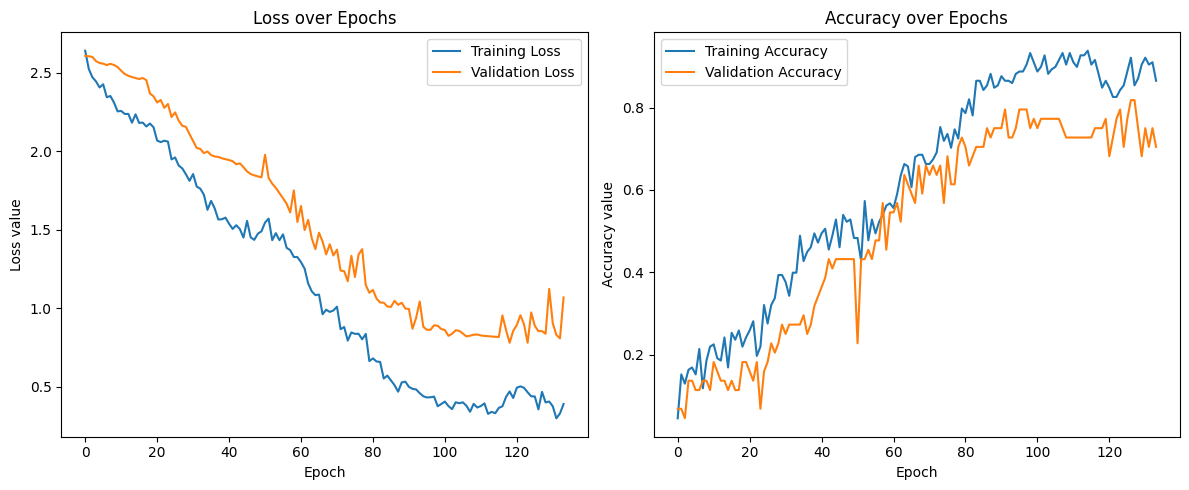

In [31]:
import matplotlib.pyplot as plt

# print(history.history.keys()) # View available metrics, e.g., ['loss', 'accuracy', 'val_loss', 'val_accuracy']

# 4. Plot training and validation loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss over Epochs')
plt.ylabel('Loss value')
plt.xlabel('Epoch')
plt.legend()

# 5. Plot training and validation accuracy (if applicable)
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.ylabel('Accuracy value')
plt.xlabel('Epoch')
plt.legend()

plt.tight_layout()
plt.show()

In [56]:
version = 9

model.save(f"models/hand_gesture_modelv{version}.keras")
model.save(f"website/models/hand_gesture_modelv{version}.keras")

In [10]:
print(find_max_length(raw_test, raw_train, raw_val))

186


In [15]:
from tensorflow.keras.models import load_model

model = load_model(f"models/hand_gesture_modelv9.keras")

probabilities = model.predict(test_X)
predictions = np.argmax(probabilities, axis=1)

print(
    classification_report(
        test_Y,
        predictions,
        target_names=[
            word_to_number[i]
            for i in range(len(word_to_number))
        ],
    )
)

print(confusion_matrix(test_Y, predictions))

1/5 ━━━━━━━━━━━━━━━━━━━━ 1s 276ms/stepWARNING:tensorflow:5 out of the last 11 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x0000024FA796CF40> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 83ms/step
              precision    recall  f1-score   support

   CLOSEEYES       0.69      0.82      0.75        11
        EYES       0.62      0.50      0.56        10
       HELLO       0.62      0.77 